<a href="https://colab.research.google.com/github/nguyentuanphong0510/Machine-Learning/blob/main/BTVN_Buoi02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#bài 1  thực nghiệm các giá trị khác nhau kernel đánh giá hiệu suất mô hình với svm
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

# Dùng bộ Breast Cancer (hoặc đổi sang load_iris() tùy ý)
data = datasets.load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

kernels = ['linear', 'poly', 'rbf', 'sigmoid']
records = []

for k in kernels:
    model = make_pipeline(StandardScaler(), SVC(kernel=k, C=1.0, gamma='scale', random_state=42))
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    records.append({
        "Kernel": k,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "F1_score": round(f1_score(y_test, y_pred, average='weighted'), 4)
    })

print("=== Đánh giá SVM theo từng Kernel ===")
print(pd.DataFrame(records).to_string(index=False))

=== Đánh giá SVM theo từng Kernel ===
 Kernel  Accuracy  F1_score
 linear    0.9737    0.9737
   poly    0.9123    0.9092
    rbf    0.9825    0.9825
sigmoid    0.9298    0.9301


In [3]:
#sử dụng gridsearchcv để tìm siêu tham số cho svm
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

data = datasets.load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(random_state=42))
])

param_grid = {
    "svc__kernel": ["linear", "rbf", "poly"],
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", "auto", 0.01, 0.1]
}

grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Bộ siêu tham số tối ưu:", grid.best_params_)
print(f"Điểm CV trung bình tốt nhất: {grid.best_score_:.4f}")

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print(f"Accuracy trên tập test: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Bộ siêu tham số tối ưu: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Điểm CV trung bình tốt nhất: 0.9802
Accuracy trên tập test: 0.9825

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



=== So sánh độ chính xác trên tập Digits ===
KNN (K=5)      : Accuracy = 0.9639
SVM (poly)     : Accuracy = 0.9722
SVM (rbf)      : Accuracy = 0.9806


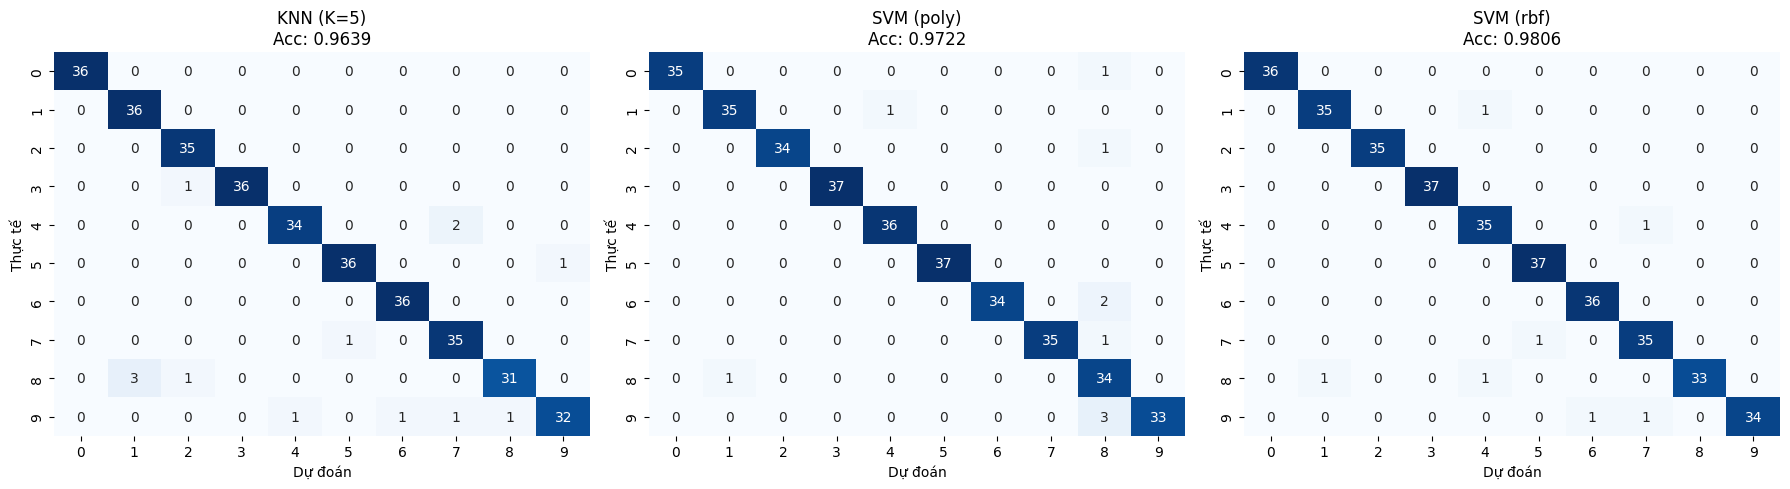

In [4]:
#Bài 3: Dùng KNN và SVM để phân loại chữ số
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Tải tập dữ liệu Digits (1797 ảnh 8x8 = 64 đặc trưng, nhãn 0..9)
digits = load_digits()
X, y = digits.data, digits.target

# 2. Chuẩn hóa dữ liệu và phân chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "KNN (K=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM (poly)": make_pipeline(StandardScaler(), SVC(kernel='poly', degree=3, C=1.0, gamma='scale')),
    "SVM (rbf)": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, gamma='scale'))
}

preds = {}
print("=== So sánh độ chính xác trên tập Digits ===")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    preds[name] = y_pred
    print(f"{name:<15}: Accuracy = {accuracy_score(y_test, y_pred):.4f}")

# 4. Hiển thị ma trận nhầm lẫn cho từng mô hình
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"{name}\nAcc: {accuracy_score(y_test, y_pred):.4f}")
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")

plt.tight_layout()
plt.show()